# 04 Score and compare (the only notebook that opens the truth)

**Task.** Score what notebooks 02 and 03 reported against the true networks. Run DMDc, output Granger, conditional
Granger and Lasso-Granger on the **same data**. Compare the power predicted by eq. (7) with the true gains with the
power observed. Show what a wrong channel sketch does.

**Reads:** `results/`, `data/truth/`, and `data/measurements/` (for the baselines and the wrong-sketch run).

**How to read the tags.** A code cell that uses a result of the paper starts with a comment such as
`# [Thm 2] threshold c_alpha`. The tag names the result; the rest of the line says what the cell does. Numbering
follows the paper: Definition 1 and Lemma 1 (first lags), Theorem 2 (certified links), Proposition 3 (lag scan),
Corollary 4 (channel certificates), Algorithm 1 and the Procedure of Section 3, equations (3) (impulse response),
(4) (residuals), (5) (the statistic), (6) (the threshold), (7) (power) and (8) (measurement duration), and the
conditions C1 (measured innovations) and C2 (predictable regressors and weights) of Theorem 2.

In [1]:
import os, sys, glob, pickle, warnings, numpy as np, pandas as pd
warnings.filterwarnings('ignore')            # scikit-learn convergence messages from the Lasso baseline
sys.path.insert(0, 'lib')
import certify as K, farmlib as FL
np.set_printoptions(precision=2, suppress=True, linewidth=150)
files = sorted(glob.glob('data/measurements/*.npz'))
SK = FL.load_sketch('data/sketch/channel_sketch.npz')
TAU, TAU0 = FL.lags(SK), FL.tau0(SK)          # lags tau_{d,o} and tau^0_c, from the sketch alone
ALPHA = 0.1
import scoring as SC, netplot as NP
truth = {os.path.splitext(os.path.basename(f))[0]: FL.load_truth(f) for f in sorted(glob.glob('data/truth/*.npz'))}
links = pickle.load(open('results/links.pkl', 'rb')); scan = pickle.load(open('results/scan.pkl', 'rb'))
print(len(truth), 'true networks;', 'mean number of links per community:',
      np.mean([((t['W'] > 0) & ~np.eye(len(t['W']), dtype=bool)).sum() for t in truth.values()]))

10 true networks; mean number of links per community: 20.5


## Is the guarantee met? (checks Theorem 2)
FWER is the share of communities with **any** false link; Theorem 2 says it is at most $\alpha=0.1$. FP is the
number of false links per community and FDR the false-discovery rate.

In [2]:
# [checks Thm 2] score every run of notebook 02
S = pd.DataFrame([dict(plan=r['plan'], years=r['years'], **SC.score(r['W_hat'], truth[r['community']]['W'])) for r in links])
S.groupby(['plan', 'years']).agg(FWER=('any_false', 'mean'), FP=('FP', 'mean'), precision=('precision', 'mean'),
                                 recall=('recall', 'mean'), F1=('F1', 'mean'), FDR=('FDR', 'mean')).round(3)

FWER   FP  precision  recall     F1  FDR
plan          years                                          
All practical 3       0.0  0.0        1.0   0.815  0.897  0.0
              5       0.0  0.0        1.0   0.967  0.983  0.0
Pump+Spray    1       0.0  0.0        1.0   0.114  0.201  0.0
              3       0.0  0.0        1.0   0.829  0.905  0.0
              5       0.0  0.0        1.0   0.972  0.986  0.0
Spray+Pest    3       0.0  0.0        1.0   0.878  0.934  0.0

In [3]:
# [checks Prop 3] the lag scan, scored
pd.DataFrame([dict(years=s['years'], **SC.score(s['W_hat'], truth[s['community']]['W'])) for s in scan]) \
  .groupby('years').agg(FWER=('any_false', 'mean'), recall=('recall', 'mean')).round(3)

,FWER,recall
years,,
3,0.0,0.756
5,0.0,0.946


## Against standard identification, on the same data (Table 2)
All methods receive soil moisture, groundwater level, pumping and spraying (the weekly survey is not given to the
baselines), the measured excitations, the canal schedule and the shared series. DMDc is a one-step least-squares
regression on all of these; output Granger uses the outputs at lags 1-3; conditional Granger adds the excitations,
canal schedules and shared series as regressors, with four lags and HAC Wald tests; Lasso-Granger fits the DMDc
regressors at lags 1 and 2 with the penalty chosen by BIC (Appendix C).

In [4]:
BASE_OUTS = ['sm', 'gw', 'pump', 'spr']
base = []
for name, t in truth.items():
    R = FL.load_measurements(f'data/measurements/{name}.npz')
    Rb = FL.view(R, 3 * 365, BASE_OUTS, [0, 1])
    res = K.baselines(Rb, BASE_OUTS, ALPHA); res['conditional_granger'] = K.conditional_granger(Rb, BASE_OUTS, 4, ALPHA)
    for meth, W_hat in res.items():
        base.append(dict(method=meth, years=3, **SC.score(W_hat, t['W'])))
ours = S[(S.plan == 'All practical') & (S.years == 3)].assign(method='ours')
B = pd.concat([ours, pd.DataFrame(base)])
B.groupby('method').agg(FWER=('any_false', 'mean'), FP=('FP', 'mean'), precision=('precision', 'mean'),
                        recall=('recall', 'mean'), F1=('F1', 'mean'), FDR=('FDR', 'mean')).round(2)

,FWER,FP,precision,recall,F1,FDR
method,,,,,,
conditional_granger,1.0,18.6,0.53,1.00,0.69,0.47
dmdc,1.0,26.1,0.44,0.99,0.61,0.56
lasso_granger,1.0,35.4,0.37,1.00,0.54,0.63
ours,0.0,0.0,1.00,0.81,0.90,0.00
output_granger,1.0,21.4,0.48,0.95,0.63,0.52


## The true network and the recovered ones
Farms sit in order along the watercourse, from the head (farm 1) to the tail. An arrow $j\to i$ means farm $i$
follows farm $j$, and its width shows the true weight $W_{ij}$. On the recovered panels:
* **blue** = found (true and reported);
* **grey dashed** = missed (true, not reported);
* **red** = false (reported, not true).

Change `COMMUNITY` to look at another community.

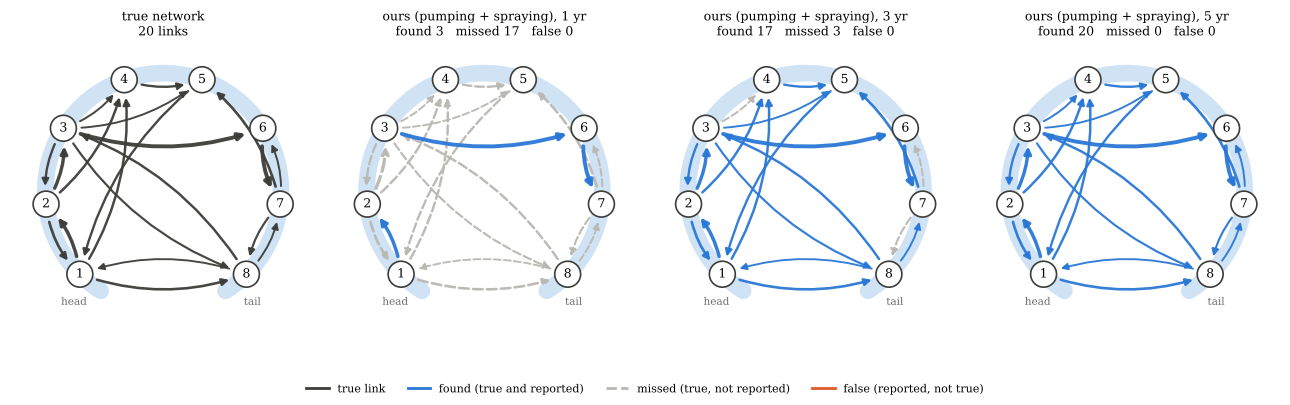

In [5]:
# [Thm 2, visually] the true network and what the test recovers as the measurement duration grows
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family': 'serif'})
COMMUNITY = 'community_00'
W = truth[COMMUNITY]['W']
get = lambda plan, yrs: [r for r in links if r['community'] == COMMUNITY and r['plan'] == plan and r['years'] == yrs][0]['W_hat']
fig, ax = plt.subplots(1, 4, figsize=(13, 3.9))
NP.draw_network(ax[0], W, None, 'true network')
for k, yrs in enumerate((1, 3, 5)):
    NP.draw_network(ax[k + 1], W, get('Pump+Spray', yrs), f'ours (pumping + spraying), {yrs} yr')
NP.network_legend(fig); fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(os.path.join('results', f'network_{COMMUNITY}_ours.png'), dpi=150); plt.show()

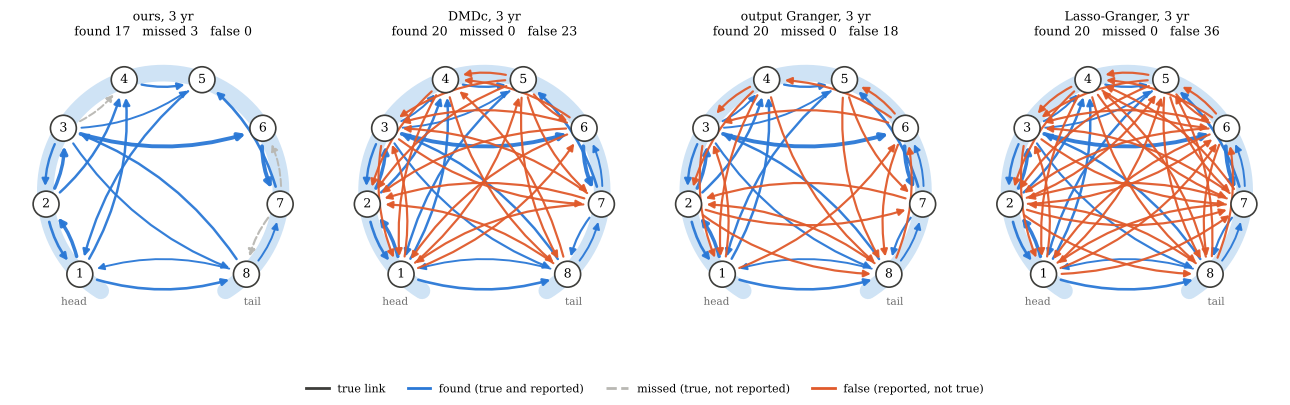

In [6]:
# the same community: ours against standard identification, all on the same 3 years of data (cf. Figure 3)
R = FL.load_measurements(os.path.join('data', 'measurements', f'{COMMUNITY}.npz'))
bd = K.baselines(FL.view(R, 3 * 365, BASE_OUTS, [0, 1]), BASE_OUTS, ALPHA)
fig, ax = plt.subplots(1, 4, figsize=(13, 3.9))
NP.draw_network(ax[0], W, get('All practical', 3), 'ours, 3 yr')
for k, (m, lab) in enumerate([('dmdc', 'DMDc'), ('output_granger', 'output Granger'), ('lasso_granger', 'Lasso-Granger')]):
    NP.draw_network(ax[k + 1], W, bd[m], f'{lab}, 3 yr')
NP.network_legend(fig); fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(os.path.join('results', f'network_{COMMUNITY}_baselines.png'), dpi=150); plt.show()

Our test draws no red arrow; with more data the grey arrows turn blue. The baselines find nearly every true
link, but surround the true links with false ones. Many of the false arrows join farms that are two steps apart
along a path (indirect paths), or farms that share the same water and weather.

## Does eq. (7) predict the power? (with the true gains)
Using the **true** impulse responses at the tested lags (eq. 3) and the residual spreads observed by the test, eq.
(7) predicts each pair's chance of being found. Compare the mean over true links with the observed share found.

In [7]:
# [eq. (7), true gains] predicted against observed power
rows = []
for r in links:
    t = truth[r['community']]; true = (t['W'] > 0) & ~np.eye(len(t['W']), dtype=bool)
    pf = SC.predicted_found(SC.with_true_gains(r['info'], t))
    rows.append(dict(plan=r['plan'], years=r['years'], predicted=pf[true].mean(), observed=SC.score(r['W_hat'], t['W'])['recall']))
pd.DataFrame(rows).groupby(['plan', 'years'])[['predicted', 'observed']].mean().round(3)

predicted  observed
plan          years                     
All practical 3          0.764     0.815
              5          0.952     0.967
Pump+Spray    1          0.069     0.114
              3          0.786     0.829
              5          0.958     0.972
Spray+Pest    3          0.827     0.878

## What a wrong channel sketch does (Proposition 3 against a fixed wrong lag)
A sketch with an extra arrow says that pest pressure acts on spraying through perceived scarcity, so lag 3, while
the true lag is 2. At lag 3 the indirect paths $j\to l\to i$ have arrived (Table 4).

In [8]:
# [Prop 3 vs a wrong lag] spraying only: lag 3 from a wrong sketch, lag 2 from the true sketch, and the lag scan
rows = []
for name, t in truth.items():
    R = FL.load_measurements(f'data/measurements/{name}.npz')
    for yrs in (3, 5):
        Rv = FL.view(R, yrs * 365, ['spr'], [1])
        _, W_wrong = K.test_excitation(Rv, 1, {'spr': 3}, ALPHA, [1], FL.SHARED, tau0=TAU0)
        _, W_true = K.test_excitation(Rv, 1, {'spr': 2}, ALPHA, [1], FL.SHARED, tau0=TAU0)
        W_scan, _ = K.lag_scan(Rv, FL.plan('Spray+Pest'), ALPHA)
        for lab, Wh in (('wrong sketch, lag 3', W_wrong), ('true sketch, lag 2', W_true), ('lag scan', W_scan)):
            rows.append(dict(method=lab, years=yrs, **SC.score(Wh, t['W'])))
pd.DataFrame(rows).groupby(['method', 'years']).agg(FWER=('any_false', 'mean'), FP=('FP', 'mean'),
                                                    recall=('recall', 'mean')).round(2)

FWER   FP  recall
method              years                   
lag scan            3       0.0  0.0    0.82
                    5       0.0  0.0    0.97
true sketch, lag 2  3       0.0  0.0    0.88
                    5       0.0  0.0    0.98
wrong sketch, lag 3 3       0.3  0.3    0.30
                    5       0.9  1.7    0.51

## The paper's full runs (40 communities, up to 10 years)
The paper's numbers come from the scripts in `paper_runs/` (see `paper_runs/README.md`). Their saved results are
included, so the cells below only load them. `paper_runs/farm/farm_tables.py` writes Tables 2-4 from the same
file.

In [9]:
import json
F = json.load(open(os.path.join('paper_runs', 'farm', 'results', 'farm_summary.json')))
print('farm: all 11 plans x 5 durations x 40 communities -> runs with a false link =',
      F['plans_total']['runs_with_false'], '/', F['plans_total']['runs'])
print('farm: placebo statistics, mean %.3f, s.d. %.3f over %d pairs' % (F['placebo']['mean'], F['placebo']['sd'], F['placebo']['n']))
pd.DataFrame([r for r in F['plans'] if r['yrs'] != 'T90']).pivot_table(index='plan', columns='yrs', values='recall').round(2)

farm: all 11 plans x 5 durations x 40 communities -> runs with a false link = 0 / 2200
farm: placebo statistics, mean 0.017, s.d. 1.004 over 17920 pairs


yrs,1,2,3,5,10
plan,,,,,
All practical,0.09,0.58,0.81,0.96,1.00
Decoys,0.00,0.00,0.00,0.00,0.00
GW level,0.00,0.00,0.00,0.00,0.00
Pump,0.00,0.00,0.01,0.09,0.40
Pump+Spray,0.11,0.60,0.82,0.96,1.00
"Pump+Spray, no shared",0.05,0.47,0.69,0.90,0.99
SM,0.00,0.00,0.00,0.00,0.00
SM+Pump,0.00,0.00,0.00,0.08,0.36
SM+Pump(4 farms),0.00,0.00,0.00,0.05,0.20


In [10]:
# Table 2 (full run): every method on the same data
pd.DataFrame(F['baselines']).set_index(['method', 'yrs'])[['FWER', 'FP', 'precision', 'recall', 'F1', 'FDR']].round(2)

FWER     FP  precision  recall    F1   FDR
method              yrs                                            
dmdc                3     1.0  26.75       0.43    0.99  0.60  0.57
output_granger      3     1.0  21.30       0.47    0.94  0.63  0.53
lasso_granger       3     1.0  35.67       0.36    1.00  0.53  0.64
dmdc                5     1.0  31.42       0.39    1.00  0.56  0.61
output_granger      5     1.0  29.35       0.41    1.00  0.58  0.59
lasso_granger       5     1.0  35.67       0.36    1.00  0.53  0.64
ours                3     0.0   0.00       1.00    0.81  0.89  0.00
                    5     0.0   0.00       1.00    0.96  0.98  0.00
conditional_granger 3     1.0  18.75       0.52    1.00  0.68  0.48
                    5     1.0  20.15       0.51    1.00  0.67  0.49

In [11]:
# generic benchmark (Appendix D): validity and power against measurement duration, 40 networks of 20 agents
G = json.load(open(os.path.join('paper_runs', 'generic', 'paper_summary.json')))
pd.DataFrame(G['E1']['table'])[['T', 'FWER_0.05', 'FWER_0.1', 'FWER_0.2', 'power_0.1', 'pred_0.1', 'naive_FWER']].round(3)

,T,FWER_0.05,FWER_0.1,FWER_0.2,power_0.1,pred_0.1,naive_FWER
0,1000,0.0,0.0,0.0,0.328,0.318,0.150
1,2000,0.0,0.0,0.0,0.833,0.831,0.075
2,3000,0.0,0.0,0.0,0.955,0.955,0.050
3,4000,0.0,0.0,0.0,0.987,0.988,0.075
4,6000,0.0,0.0,0.0,0.998,0.999,0.100
